# 04 · Model training, comparison, tuning and threshold selection
Training is run with `python -m src.train` (takes a while); this notebook presents its saved outputs.
* CV: 5-fold **StratifiedGroupKFold** grouped by card on a stratified 30% sample of train.
* Tuning: RandomizedSearchCV scored on PR-AUC.
* Threshold and risk tiers: chosen on out-of-fold predictions over the full train set.
* Test set (later time period): used once at the end.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
from src import config
R = config.REPORTS_DIR

## Class-imbalance strategies (metrics at threshold 0.5)

In [2]:
pd.read_csv(R / 'imbalance_strategy_comparison.csv')[['model','strategy','precision','recall','f1','roc_auc','pr_auc','pr_auc_std']].round(4)

,model,strategy,precision,recall,f1,roc_auc,pr_auc,pr_auc_std
0,Logistic Regression,none,0.8013,0.2997,0.4356,0.9348,0.4600,0.0207
1,Logistic Regression,class_weight,0.0412,0.8739,0.0786,0.9496,0.2525,0.0193
2,Logistic Regression,smote,0.2498,0.6079,0.3540,0.9467,0.3543,0.0122
3,Random Forest,none,0.9567,0.6341,0.7620,0.9920,0.8687,0.0159
4,Random Forest,class_weight,0.7420,0.8046,0.7719,0.9941,0.8459,0.0185
5,XGBoost,none,0.9552,0.7842,0.8610,0.9979,0.9253,0.0099
6,XGBoost,scale_pos_weight,0.8366,0.8748,0.8551,0.9978,0.9281,0.0090
7,XGBoost,smote,0.9456,0.8095,0.8722,0.9976,0.9303,0.0100


## Model comparison (`reports/model_comparison.csv`)

In [3]:
pd.read_csv(R / 'model_comparison.csv').round(4)

,model,strategy,evaluation,precision,recall,f1,roc_auc,pr_auc,accuracy,pr_auc_std,oof_tn,oof_fp,oof_fn,oof_tp
0,Logistic Regression,none,"5-fold StratifiedGroupKFold (CV sample), thres...",0.8013,0.2997,0.4356,0.9348,0.4600,0.9955,0.0207,386582,169,1577,675
1,Random Forest,none,"5-fold StratifiedGroupKFold (CV sample), thres...",0.9567,0.6341,0.7620,0.9920,0.8687,0.9977,0.0159,386685,66,824,1428
2,XGBoost,smote,"5-fold StratifiedGroupKFold (CV sample), thres...",0.9456,0.8095,0.8722,0.9976,0.9303,0.9986,0.0100,386646,105,429,1823
3,XGBoost (tuned),tuned,"5-fold StratifiedGroupKFold (CV sample), thres...",0.9577,0.7931,0.8675,0.9979,0.9313,0.9986,0.0098,386672,79,466,1786
4,Random Forest (tuned),tuned,"5-fold StratifiedGroupKFold (CV sample), thres...",0.9663,0.6843,0.8006,0.9919,0.8871,0.9980,0.0146,386696,55,711,1541


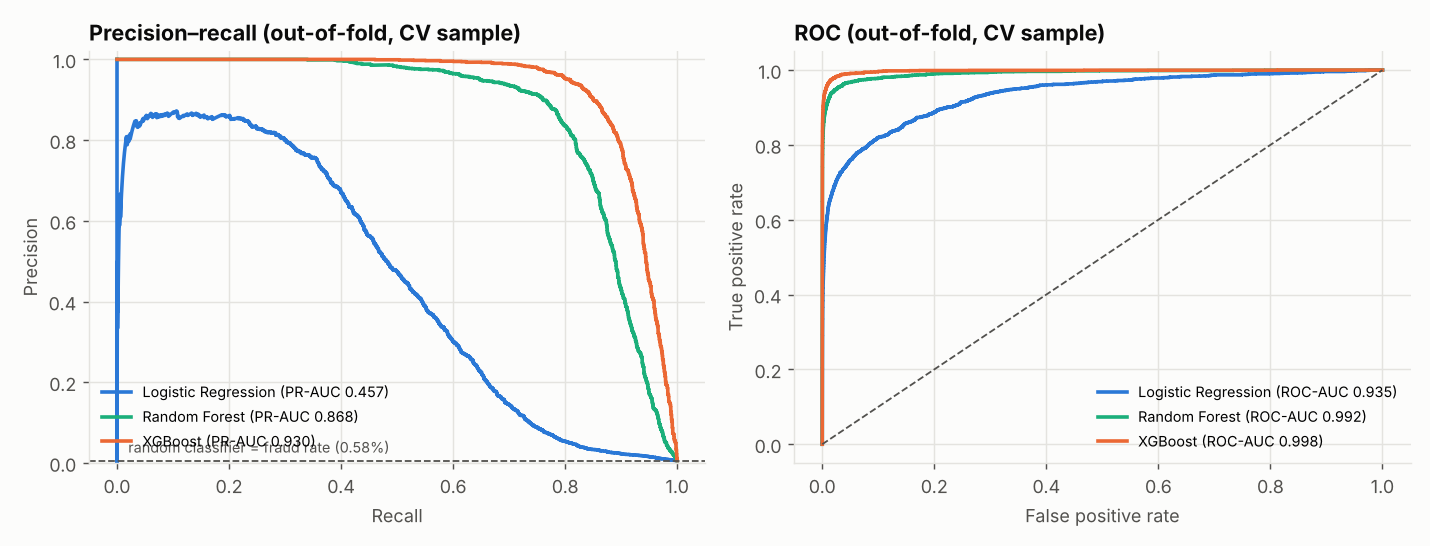

In [4]:
display(Image(filename=str(config.FIGURES_DIR / 'model_cv_pr_roc.png')))

## Hyperparameter search (top 5 XGBoost candidates)

In [5]:
t = pd.read_csv(R / 'tuning_xgboost.csv')
t[[c for c in t.columns if c.startswith('param_')] + ['mean_test_score','std_test_score']].head().round(4)

,param_model__colsample_bytree,param_model__gamma,param_model__learning_rate,param_model__max_depth,param_model__min_child_weight,param_model__n_estimators,param_model__reg_lambda,param_model__scale_pos_weight,param_model__subsample,mean_test_score,std_test_score
0,0.6915,0.3849,0.0438,8,2,756,0.3902,1.0000,0.9486,0.9249,0.0068
1,0.7694,1.9744,0.0443,9,3,792,2.6466,171.7367,0.9085,0.9245,0.0055
2,0.8546,1.5718,0.0793,8,5,606,1.6175,171.7367,0.9022,0.9244,0.0061
3,0.7247,2.6003,0.0879,8,2,755,7.5683,13.1048,0.9707,0.9228,0.0065
4,0.6391,3.4212,0.0659,9,8,234,6.5863,13.1048,0.8650,0.9200,0.0066


## Threshold analysis (out-of-fold, full train)

,threshold,precision,recall,f1,fp,fn,tp,tn,note
0,0.0122,0.5001,0.9664,0.6591,7252,252,7254,1281917,chosen (max recall s.t. precision>=0.50)
1,0.0500,0.7388,0.9361,0.8258,2484,480,7026,1286685,NaN
2,0.1000,0.8301,0.9133,0.8697,1403,651,6855,1287766,NaN
3,0.1500,0.8751,0.8982,0.8865,962,764,6742,1288207,NaN
4,0.1923,0.9000,0.8874,0.8937,740,845,6661,1288429,high-tier floor (precision>=0.90)
5,0.2000,0.9041,0.8858,0.8949,705,857,6649,1288464,NaN
6,0.2500,0.9215,0.8729,0.8966,558,954,6552,1288611,NaN
7,0.3000,0.9358,0.8626,0.8977,444,1031,6475,1288725,NaN
8,0.3209,0.9410,0.8602,0.8988,405,1049,6457,1288764,max F1
9,0.3500,0.9459,0.8542,0.8977,367,1094,6412,1288802,NaN


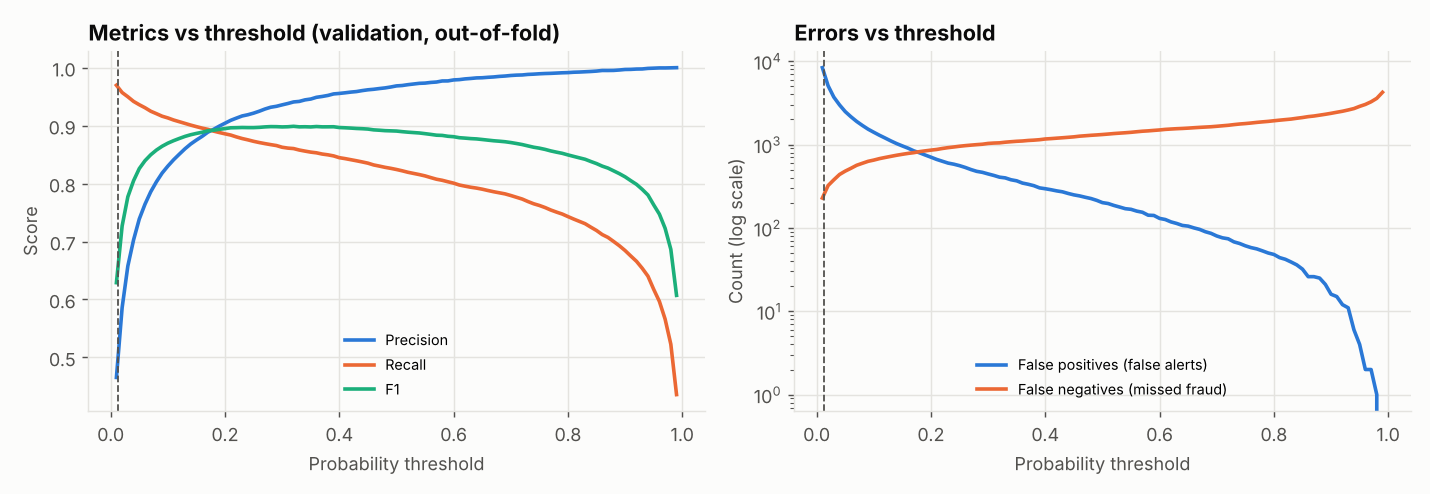

In [6]:
display(pd.read_csv(R / 'threshold_analysis.csv').round(4))
display(Image(filename=str(config.FIGURES_DIR / 'threshold_tradeoff.png')))

## Final evaluation on the out-of-time test set

,model,strategy,threshold_rule,accuracy,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp,threshold
0,Logistic Regression,none,0.5,0.9969,0.8336,0.2429,0.3762,0.9321,0.4522,553470,104,1624,521,0.5000
1,Random Forest,tuned,0.5,0.9988,0.9729,0.7203,0.8278,0.9938,0.8923,553531,43,600,1545,0.5000
2,XGBoost,tuned,0.5,0.9990,0.9768,0.7459,0.8459,0.9983,0.9208,553536,38,545,1600,0.5000
3,XGBoost,tuned,chosen,0.9967,0.5454,0.9296,0.6875,0.9983,0.9208,551912,1662,151,1994,0.0122


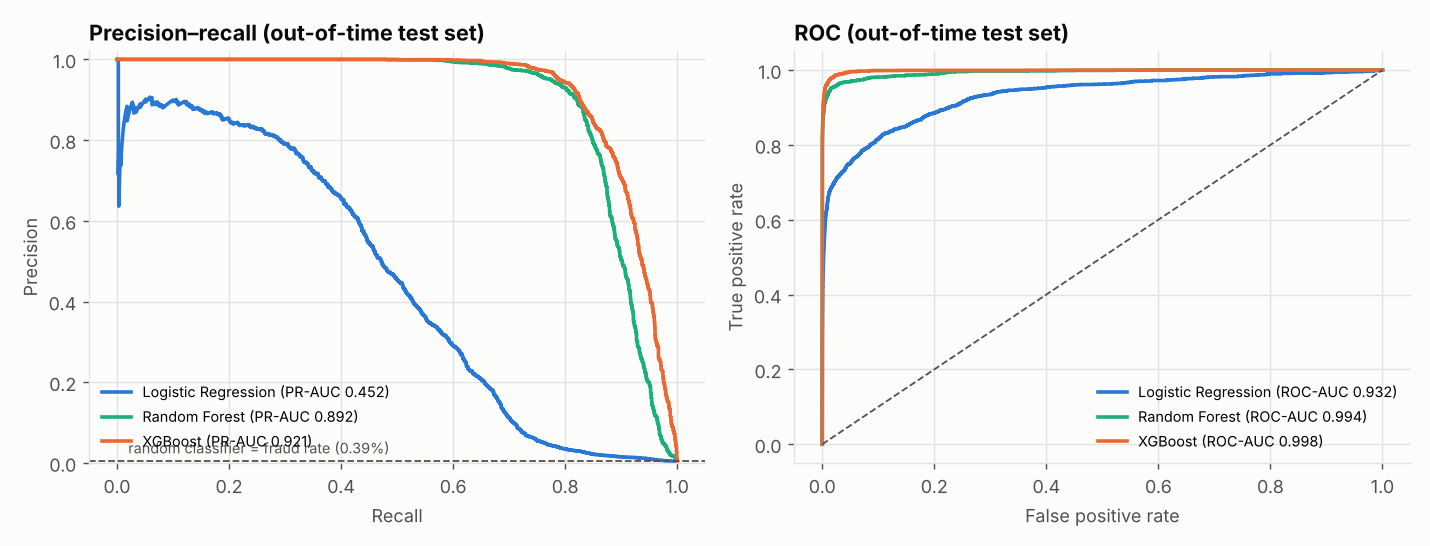

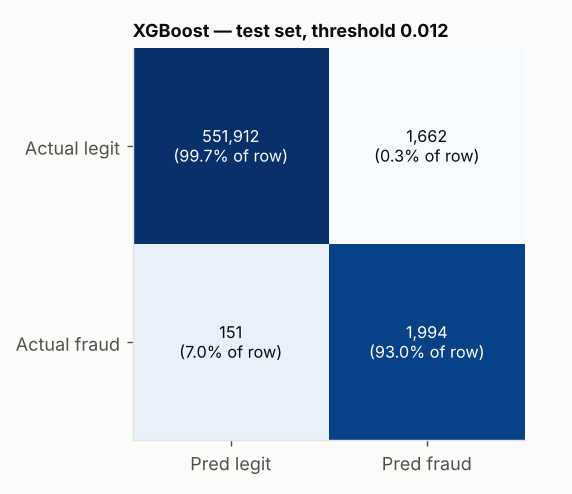

In [7]:
display(pd.read_csv(R / 'test_metrics.csv').round(4))
display(Image(filename=str(config.FIGURES_DIR / 'model_test_pr_roc.png')))
display(Image(filename=str(config.FIGURES_DIR / 'confusion_matrix_xgb_test.png')))

## Robustness: does performance rely on the new-card artefact?

In [8]:
pd.read_csv(R / 'robustness_checks.csv').round(4)

,check,pr_auc,roc_auc,threshold,precision,recall,f1,fp,fn,n_rows_removed
0,"XGBoost, all test cards",0.9208,0.9983,0.0122,0.5454,0.9296,0.6875,1662.0,151.0,NaN
1,"XGBoost, test excluding cards unseen in train",0.9117,0.9981,0.0122,0.5243,0.9243,0.6691,1662.0,150.0,163.0
2,"XGBoost without card_prior_txn_count, all test...",0.9174,0.9981,NaN,NaN,NaN,NaN,NaN,NaN,NaN
